In [2]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, classification_report)

tf.keras.utils.set_random_seed(42)

data = np.load("../data/sign_mnist_prepared.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

with open("../data/idx_to_letter.json") as f:
    idx_to_letter = {int(k): v for k, v in json.load(f).items()}
letters = [idx_to_letter[i] for i in range(24)]

In [3]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(24, activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_cnn()

In [4]:
augment_strong = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(height_factor=(-0.3, 0.3), width_factor=(-0.3, 0.3)),
    layers.RandomTranslation(0.15, 0.15),
    layers.RandomBrightness(0.3, value_range=(0, 1)),
    layers.RandomContrast(0.4),
    layers.GaussianNoise(0.05),
], name="augmentation_forte")

def apply_aug(x, y):
    x = augment_strong(x, training=True)
    return tf.clip_by_value(x, 0.0, 1.0), y

In [5]:
n_val = int(0.15 * len(X_train))
perm = np.random.default_rng(42).permutation(len(X_train))
val_idx, tr_idx = perm[:n_val], perm[n_val:]

X_val, y_val = X_train[val_idx], y_train[val_idx]
X_tr, y_tr = X_train[tr_idx], y_train[tr_idx]

train_ds = (tf.data.Dataset.from_tensor_slices((X_tr, y_tr))
            .shuffle(10000, seed=42)
            .batch(64)
            .map(apply_aug, num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(64)

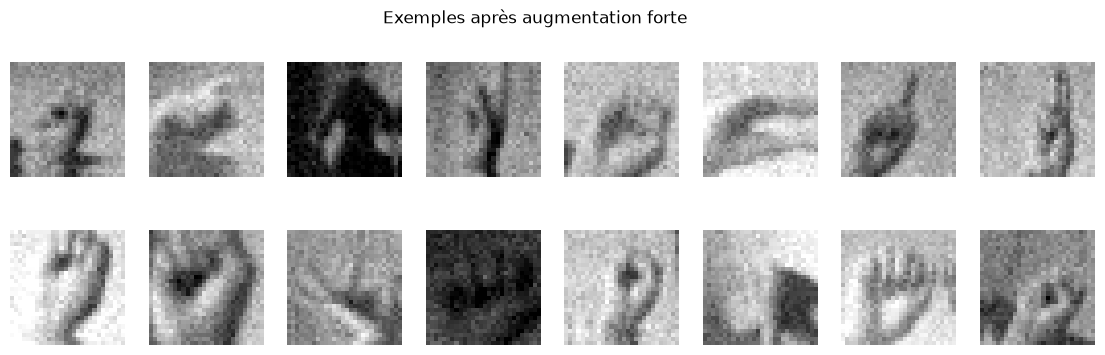

In [6]:
x_batch, _ = next(iter(train_ds))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img in zip(axes.ravel(), x_batch[:16]):
    ax.imshow(img.numpy().squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("Exemples après augmentation forte")
plt.show()

In [7]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=8,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=3, min_lr=1e-5),
]

start = time.time()
history = model.fit(train_ds, validation_data=val_ds,
                    epochs=50, callbacks=callbacks, verbose=1)
print(f"Temps d'entraînement : {time.time() - start:.0f} s")

Epoch 1/50


c:\Users\Malak\OneDrive\Documents\S2_EMSI\DM\projet_sign_language\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


365/365 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.2260 - loss: 2.7522 - val_accuracy: 0.1217 - val_loss: 2.8306 - learning_rate: 0.0010
Epoch 2/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 54s 131ms/step - accuracy: 0.5031 - loss: 1.5292 - val_accuracy: 0.8553 - val_loss: 0.5339 - learning_rate: 0.0010
Epoch 3/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 38s 104ms/step - accuracy: 0.6470 - loss: 1.0621 - val_accuracy: 0.8694 - val_loss: 0.4304 - learning_rate: 0.0010
Epoch 4/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - accuracy: 0.7255 - loss: 0.8195 - val_accuracy: 0.9636 - val_loss: 0.1643 - learning_rate: 0.0010
Epoch 5/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 73s 200ms/step - accuracy: 0.7788 - loss: 0.6536 - val_accuracy: 0.9284 - val_loss: 0.1902 - learning_rate: 0.0010
Epoch 6/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 53s 143ms/step - accuracy: 0.8158 - loss: 0.5494 - val_accuracy: 0.9740 - val_loss: 0.0990 - learning_rate: 0.0010
Epoch 7/50
365/365 ━━━━━━━━━━━━━━━━━━━━ 50s 137ms/step - accuracy: 0.8412 - loss: 

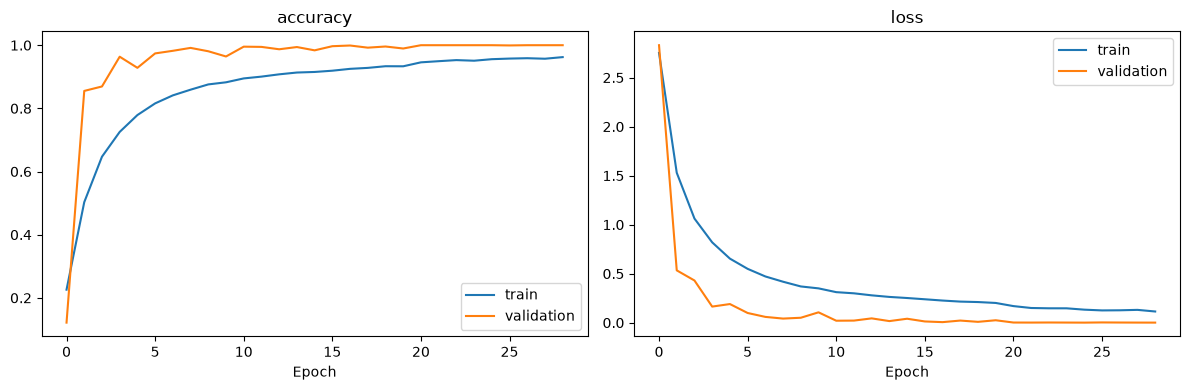

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axes, ["accuracy", "loss"]):
    ax.plot(history.history[m], label="train")
    ax.plot(history.history[f"val_{m}"], label="validation")
    ax.set_title(m); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout()
plt.show()

In [9]:
proba = model.predict(X_test, verbose=0)
y_pred = proba.argmax(axis=1)

res_robust = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision_macro": float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
    "recall_macro": float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
    "f1_macro": float(f1_score(y_test, y_pred, average="macro")),
}
print({k: round(v, 4) for k, v in res_robust.items()})
print("Accuracy >= 90 % :", "OK" if res_robust["accuracy"] >= 0.90 else "NON ATTEINT")
print("F1 macro >= 90 % :", "OK" if res_robust["f1_macro"] >= 0.90 else "NON ATTEINT")

{'accuracy': 0.999, 'precision_macro': 0.999, 'recall_macro': 0.9988, 'f1_macro': 0.9989}
Accuracy >= 90 % : OK
F1 macro >= 90 % : OK


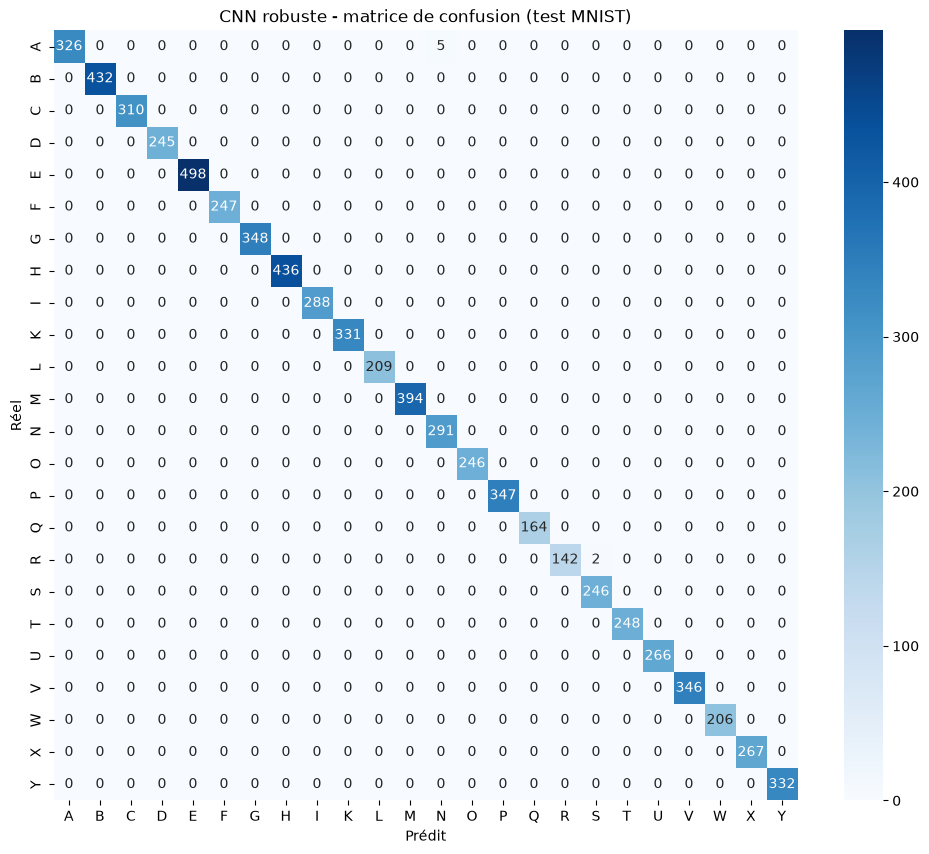

              precision    recall  f1-score   support

           A      1.000     0.985     0.992       331
           B      1.000     1.000     1.000       432
           C      1.000     1.000     1.000       310
           D      1.000     1.000     1.000       245
           E      1.000     1.000     1.000       498
           F      1.000     1.000     1.000       247
           G      1.000     1.000     1.000       348
           H      1.000     1.000     1.000       436
           I      1.000     1.000     1.000       288
           K      1.000     1.000     1.000       331
           L      1.000     1.000     1.000       209
           M      1.000     1.000     1.000       394
           N      0.983     1.000     0.991       291
           O      1.000     1.000     1.000       246
           P      1.000     1.000     1.000       347
           Q      1.000     1.000     1.000       164
           R      1.000     0.986     0.993       144
           S      0.992    

In [10]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=letters, yticklabels=letters)
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.title("CNN robuste - matrice de confusion (test MNIST)")
plt.show()

print(classification_report(y_test, y_pred, target_names=letters, digits=3))

In [11]:
model.save("../data/cnn_robuste.keras")

with open("../docs/results.json") as f:
    results = json.load(f)
results["cnn_robuste"] = res_robust
with open("../docs/results.json", "w") as f:
    json.dump(results, f, indent=2)